# EDA — Competencia crediticia

Esta es una exploración propia de `data/raw/train.csv`, pensada como complemento al EDA de `01_eda.ipynb`. La idea es ver los datos desde otros ángulos: buscar atípicos con un criterio más explícito (la regla del rango intercuartílico), revisar si hay variables cuya relación con el impago no es lineal, y medir qué tan bien predice cada variable por separado usando Information Value/WOE (frecuente en scoring crediticio) y la información mutua.

Variable objetivo: `SeriousDlqin2yrs` (1 = la persona tuvo problemas financieros serios en los siguientes 2 años). La competencia se evalúa con AUC-ROC.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Carga de datos y panorama general

In [2]:
train = pd.read_csv("../data/raw/train.csv")

TARGET, ID = "SeriousDlqin2yrs", "Id"
FEATS = [c for c in train.columns if c not in (TARGET, ID)]
LATE = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
]

print("Filas y columnas:", train.shape)
train.head()

Filas y columnas: (105000, 12)


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,139333,0,0.2689,55,0,7.7105,600.0000,10,0,2,0,0.0000
1,40087,0,0.1362,32,0,0.4638,"4,300.0000",2,0,1,0,0.0000
2,75114,0,0.5950,48,0,58.0000,NaN,2,0,0,0,NaN
3,44118,0,0.0540,48,0,0.2332,"8,051.0000",7,0,1,0,0.0000
4,65721,0,0.0979,43,1,0.1615,"4,000.0000",12,0,0,0,0.0000


In [3]:
resumen = pd.DataFrame({
    "dtype": train.dtypes,
    "n_unique": train.nunique(),
    "nulos": train.isna().sum(),
    "%_nulos": (train.isna().mean() * 100).round(2),
})
print("Memoria total:", round(train.memory_usage(deep=True).sum() / 1024**2, 2), "MB")
resumen

Memoria total: 9.61 MB


,dtype,n_unique,nulos,%_nulos
Id,int64,105000,0,0.0000
SeriousDlqin2yrs,int64,2,0,0.0000
RevolvingUtilizationOfUnsecuredLines,float64,88528,0,0.0000
age,int64,83,0,0.0000
NumberOfTime30-59DaysPastDueNotWorse,int64,16,0,0.0000
DebtRatio,float64,82380,0,0.0000
MonthlyIncome,float64,12073,20828,19.8400
NumberOfOpenCreditLinesAndLoans,int64,57,0,0.0000
NumberOfTimes90DaysLate,int64,18,0,0.0000
NumberRealEstateLoansOrLines,int64,28,0,0.0000


## 2. Calidad de datos: identificador y duplicados

In [4]:
print("Id únicos:", train[ID].is_unique)
print("Filas duplicadas (ignorando Id):", train.drop(columns=ID).duplicated().sum())
print("Rango de Id:", train[ID].min(), "-", train[ID].max(), "| filas en train:", len(train))

Id únicos: True
Filas duplicadas (ignorando Id): 339
Rango de Id: 2 - 149999 | filas en train: 105000


Si ignoramos el `Id`, sí aparecen filas duplicadas (339). El `Id` en sí es único, pero su rango llega hasta ~150,000 mientras que solo tenemos 105,000 filas — es decir, no es un índice continuo de 0 a n. Las filas duplicadas quedan como algo a decidir más adelante: ¿son clientes repetidos o coincidencias de un dataset con pocas variables? Esrto es sospechoso en variables con decimales.

## 3. Variable objetivo: balance de clases

Tasa de impago: 0.0668 (7,018 de 105,000)
Razón de desbalance: 1 caso positivo por cada 14.0 negativos


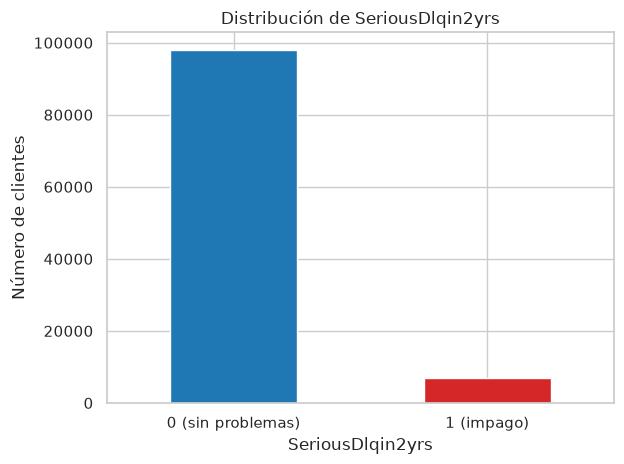

In [5]:
rate = train[TARGET].mean()
print(f"Tasa de impago: {rate:.4f} ({train[TARGET].sum():,} de {len(train):,})")
print(f"Razón de desbalance: 1 caso positivo por cada {(1 - rate) / rate:.1f} negativos")

ax = train[TARGET].value_counts().sort_index().plot(
    kind="bar", color=["#1f77b4", "#d62728"], title="Distribución de SeriousDlqin2yrs"
)
ax.set_xticklabels(["0 (sin problemas)", "1 (impago)"], rotation=0)
ax.set_ylabel("Número de clientes")
plt.tight_layout()
plt.show()

El desbalance es moderado: alrededor de 6.7% de los clientes tuvo impago, es decir, más o menos 1 caso positivo por cada 14 negativos. No es tan extremo como para necesitar técnicas de remuestreo agresivas, pero sí conviene validar con folds estratificados y medir con AUC-ROC en vez de accuracy, que con esta proporción de clases resultaría engañoso.

## 4. Valores faltantes: ¿son aleatorios?

In [6]:
faltantes = train[FEATS].isna().mean().loc[lambda s: s > 0].sort_values(ascending=False)
print("Columnas con nulos (% del total):")
print((faltantes * 100).round(2))

# ¿La ausencia del dato está asociada con mayor o menor riesgo?
for col in faltantes.index:
    tasa = train.groupby(train[col].isna())[TARGET].mean()
    print(f"\n{col}: tasa de impago con dato presente = {tasa[False]:.4f} | con dato faltante = {tasa[True]:.4f}")

Columnas con nulos (% del total):
MonthlyIncome        19.8400
NumberOfDependents    2.6400
dtype: float64

MonthlyIncome: tasa de impago con dato presente = 0.0695 | con dato faltante = 0.0561



NumberOfDependents: tasa de impago con dato presente = 0.0673 | con dato faltante = 0.0480


Sólo dos columnas tienen valores faltantes: `MonthlyIncome` (19.8%) y `NumberOfDependents` (2.6%). Y en ambos casos pasa algo interesante: la tasa de impago es menor cuando el dato falta que cuando está presente. Eso sugiere que la ausencia no es aleatoria (puede ser informativa) así que conviene guardarla como una bandera (`*_missing`) en vez de sólo imputar.

## 5. Estadísticas descriptivas y atípicos (regla IQR)

In [7]:
train[FEATS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).T

,count,mean,std,min,1%,25%,50%,75%,95%,99%,99.9%,max
RevolvingUtilizationOfUnsecuredLines,"105,000.0000",6.4124,273.6434,0.0000,0.0000,0.0299,0.1543,0.5606,1.0000,1.0922,"1,577.0430","50,708.0000"
age,"105,000.0000",52.2872,14.7763,0.0000,24.0000,41.0000,52.0000,63.0000,78.0000,87.0000,94.0000,103.0000
NumberOfTime30-59DaysPastDueNotWorse,"105,000.0000",0.4293,4.2866,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,4.0000,98.0000,98.0000
DebtRatio,"105,000.0000",358.3275,"2,318.2649",0.0000,0.0000,0.1742,0.3664,0.8706,"2,457.0500","5,011.0100","10,930.2650","329,664.0000"
MonthlyIncome,"84,172.0000","6,645.4921","15,507.7940",0.0000,0.0000,"3,400.0000","5,400.0000","8,208.0000","14,550.0000","25,000.0000","75,000.0000","3,008,750.0000"
NumberOfOpenCreditLinesAndLoans,"105,000.0000",8.4439,5.1319,0.0000,0.0000,5.0000,8.0000,11.0000,18.0000,24.0000,34.0000,58.0000
NumberOfTimes90DaysLate,"105,000.0000",0.2746,4.2639,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,3.0000,98.0000,98.0000
NumberRealEstateLoansOrLines,"105,000.0000",1.0176,1.1424,0.0000,0.0000,0.0000,1.0000,2.0000,3.0000,4.0000,9.0000,54.0000
NumberOfTime60-89DaysPastDueNotWorse,"105,000.0000",0.2484,4.2498,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,98.0000,98.0000
NumberOfDependents,"102,229.0000",0.7572,1.1138,0.0000,0.0000,0.0000,0.0000,1.0000,3.0000,4.0000,6.0000,13.0000


In [8]:
def outliers_iqr(serie):
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = (s < low) | (s > high)
    return pd.Series({
        "limite_inferior": low, "limite_superior": high,
        "n_atipicos": atipicos.sum(), "%_atipicos": round(atipicos.mean() * 100, 2),
    })


tabla_iqr = pd.DataFrame({c: outliers_iqr(train[c]) for c in FEATS}).T
tabla_iqr.sort_values("%_atipicos", ascending=False)

,limite_inferior,limite_superior,n_atipicos,%_atipicos
DebtRatio,-0.8703,1.9151,"21,939.0000",20.8900
NumberOfTime30-59DaysPastDueNotWorse,0.0000,0.0000,"16,749.0000",15.9500
NumberOfDependents,-1.5000,2.5000,"9,371.0000",9.1700
NumberOfTimes90DaysLate,0.0000,0.0000,"5,843.0000",5.5600
NumberOfTime60-89DaysPastDueNotWorse,0.0000,0.0000,"5,304.0000",5.0500
MonthlyIncome,"-3,812.0000","15,420.0000","3,451.0000",4.1000
NumberOfOpenCreditLinesAndLoans,-4.0000,20.0000,"2,768.0000",2.6400
NumberRealEstateLoansOrLines,-3.0000,5.0000,565.0000,0.5400
RevolvingUtilizationOfUnsecuredLines,-0.7662,1.3567,543.0000,0.5200
age,8.0000,96.0000,29.0000,0.0300


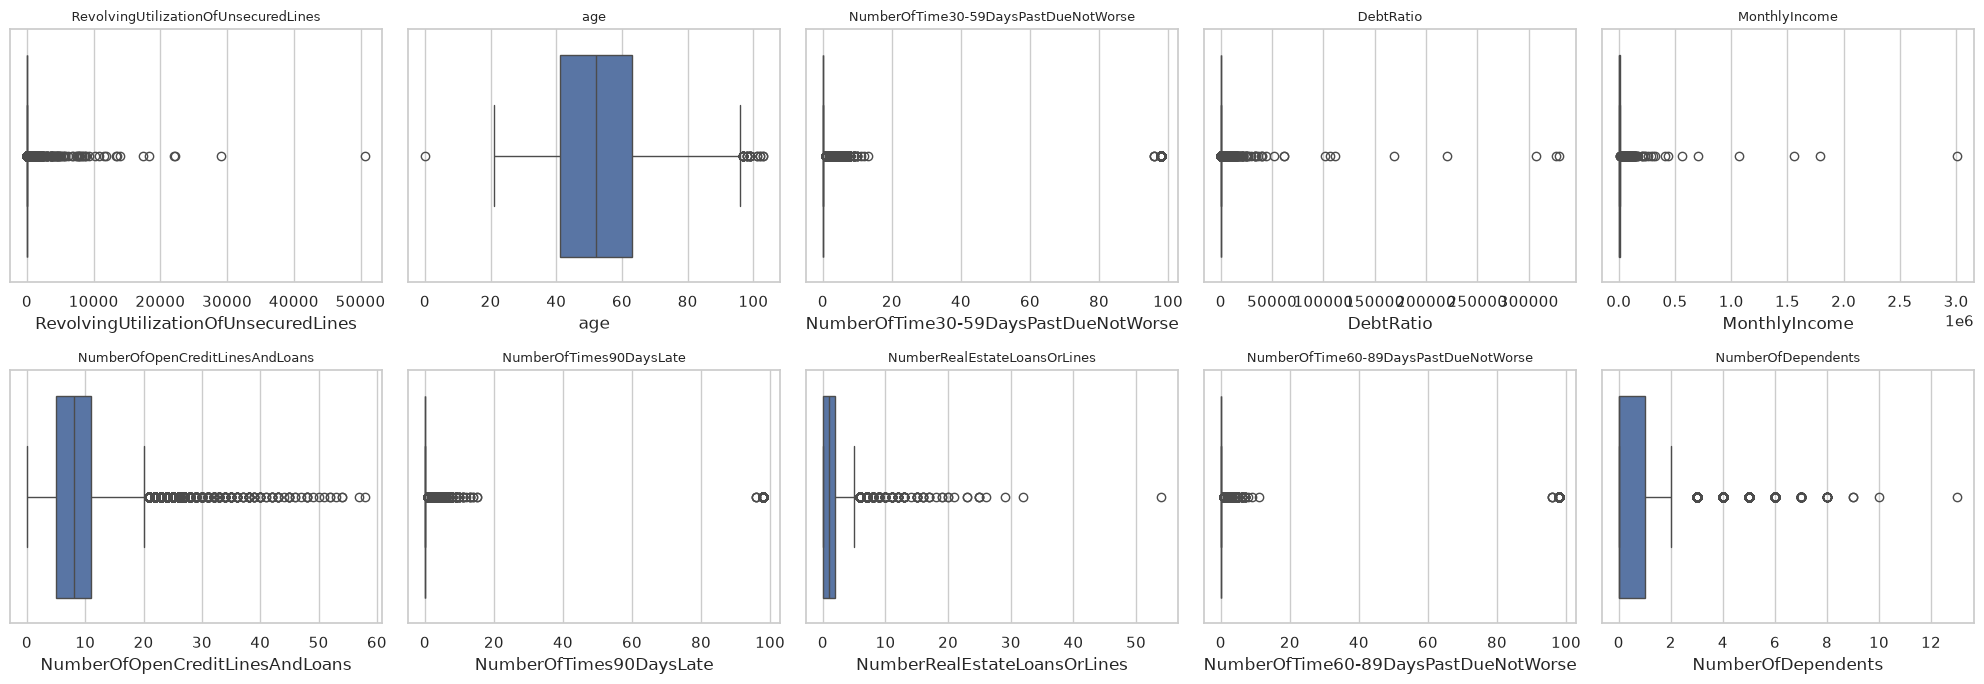

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.ravel(), FEATS):
    sns.boxplot(x=train[c].dropna(), ax=ax, color="#4c72b0")
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

Con el criterio del rango intercuartílico, `DebtRatio` es la variable con más atípicos (cerca de 21%) y `RevolvingUtilizationOfUnsecuredLines` también se sale bastante, lo que tiene sentido porque ambas tienen colas largas (máximos de 329,664 y 50,708). Las tres columnas de atraso marcan como atípico casi cualquier valor distinto de 0, porque la mediana y el percentil 75 son 0 (aquí este criterio no ayuda mucho). Aquí no son atípicos reales sino los códigos 96/98, que se ven como puntos sueltos muy a la derecha en los boxplots (datos faltantes disfrazados de número, no conteos de verdad).

## 6. Relaciones no lineales: tasa de impago en variables de conteo

El EDA anterior encontró una correlación de Spearman casi nula para `NumberOfOpenCreditLinesAndLoans` y `NumberRealEstateLoansOrLines`. Pero una correlación sólo detecta relaciones que van siempre en la misma dirección: si el riesgo primero sube y después baja (o al revés) a medida que cambia la variable, puede salir un número cercano a cero aunque la relación sí sea fuerte. Por eso conviene revisar la tasa de impago nivel por nivel.

In [10]:
def tasa_por_nivel(col, tope_pct=0.98):
    s = train[col].fillna(-1)
    tope = s[s >= 0].quantile(tope_pct)
    s = s.clip(upper=tope)
    return train.groupby(s)[TARGET].agg(tasa_impago="mean", n="count")


niveles = {
    "NumberOfDependents": tasa_por_nivel("NumberOfDependents"),
    "NumberOfOpenCreditLinesAndLoans": tasa_por_nivel("NumberOfOpenCreditLinesAndLoans"),
    "NumberRealEstateLoansOrLines": tasa_por_nivel("NumberRealEstateLoansOrLines"),
}
for col, tabla in niveles.items():
    print(f"\n{col}")
    print(tabla.round(3))


NumberOfDependents
                    tasa_impago      n
NumberOfDependents                    
-1.0000                  0.0480   2771
0.0000                   0.0590  60792
1.0000                   0.0720  18479
2.0000                   0.0820  13587
3.0000                   0.0910   6695
4.0000                   0.0980   2676

NumberOfOpenCreditLinesAndLoans
                                 tasa_impago     n
NumberOfOpenCreditLinesAndLoans                   
0                                     0.2560  1365
1                                     0.1320  3162
2                                     0.0930  4612
3                                     0.0740  6387
4                                     0.0650  8041
5                                     0.0610  9023
6                                     0.0540  9586
7                                     0.0570  9230
8                                     0.0480  8750
9                                     0.0600  7975
10                     

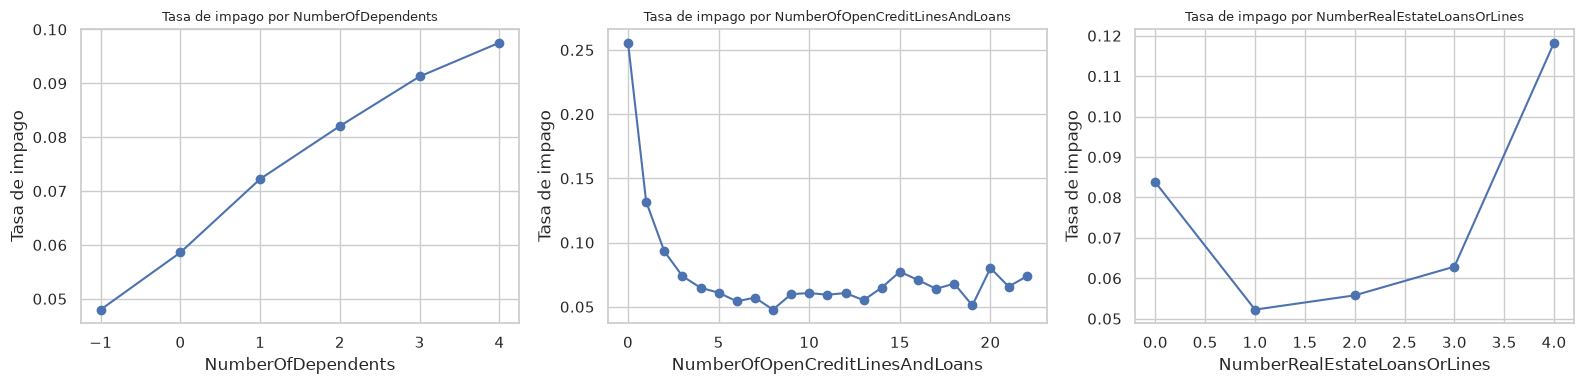

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, tabla) in zip(axes, niveles.items()):
    ax.plot(tabla.index, tabla["tasa_impago"], marker="o")
    ax.set_title(f"Tasa de impago por {col}", fontsize=9)
    ax.set_xlabel(col)
    ax.set_ylabel("Tasa de impago")
plt.tight_layout()
plt.show()

Observamos que:
- `NumberOfOpenCreditLinesAndLoans` tiene forma de U: con 0 líneas de crédito abiertas el impago llega a ~26% (el nivel más alto de toda la variable), baja hasta ~5% entre 6 y 9 líneas, y vuelve a subir un poco a partir de 20+. O sea que tener cero líneas no significa "sin riesgo", pueden ser de personas sin historial crediticio o que ya cerraron todo, y son el grupo más riesgoso. Por eso su Spearman salía casi en cero (-0.04): la relación no es monótona, así que la correlación no la capta.
- `NumberRealEstateLoansOrLines` se comporta parecido: 0 préstamos -> 8.4%, el mínimo está en 1-2 préstamos (5.2%-5.6%), y vuelve a subir con 3-4+ (6.3%-11.8%). Ni tener cero propiedades ni tener varias es lo más seguro.
- `NumberOfDependents` sí es simple y monótona: más dependientes, más impago (5.9% con 0 hasta 9.8% con 4 o más), lo que tiene sentido si pensamos en la presión que meten más personas a cargo sobre el ingreso disponible.

Vale la pena hacer una bandera `sin_lineas_credito` (`NumberOfOpenCreditLinesAndLoans == 0`) y, si se usa un modelo que no capta las relaciones no lineales solito (como la regresión logística), hay que discretizar estas dos variables en tramos en vez de dejarlas continuas. Un árbol o LightGBM debería captar esto sin ayuda.

## 7. Información mutua vs. correlación de Spearman

La información mutua no asume que la relación sea una línea recta ni que vaya siempre en la misma dirección, así que sirve para confirmar si esa forma de U que vimos antes realmente aporta algo, comparada con lo que ya medía Spearman en `01_eda.ipynb`.

In [12]:
X = train[FEATS].copy()
for c in FEATS:
    X[c] = X[c].fillna(X[c].median())

mi = pd.Series(
    mutual_info_classif(X, train[TARGET], random_state=42),
    index=FEATS, name="informacion_mutua",
).sort_values(ascending=False)

spearman = train[FEATS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).abs()
spearman.name = "spearman_abs"

comparacion = pd.concat([mi, spearman], axis=1)
comparacion["ranking_mi"] = comparacion["informacion_mutua"].rank(ascending=False).astype(int)
comparacion["ranking_spearman"] = comparacion["spearman_abs"].rank(ascending=False).astype(int)
comparacion.sort_values("informacion_mutua", ascending=False).round(4)

,informacion_mutua,spearman_abs,ranking_mi,ranking_spearman
RevolvingUtilizationOfUnsecuredLines,0.0367,0.2405,1,4
NumberOfTimes90DaysLate,0.0306,0.3422,2,1
NumberOfTime30-59DaysPastDueNotWorse,0.0258,0.2537,3,3
NumberOfTime60-89DaysPastDueNotWorse,0.0223,0.2751,4,2
age,0.0072,0.1192,5,5
NumberRealEstateLoansOrLines,0.0049,0.0360,6,9
NumberOfOpenCreditLinesAndLoans,0.0039,0.0388,7,8
DebtRatio,0.0035,0.0193,8,10
MonthlyIncome,0.0032,0.0679,9,6
NumberOfDependents,0.0026,0.0463,10,7


Y efectivamente, `NumberOfOpenCreditLinesAndLoans` y `NumberRealEstateLoansOrLines` suben bastante en el ranking de información mutua comparado con el de Spearman. Las tres variables de atraso y la utilización de crédito siguen dominando en ambos rankings. Lo que esto confirma es que la señal de esas dos variables es real, sólo que no lineal, así que un modelo lineal necesitaría ayuda (bins, interacciones) para aprovecharla.

## 8. Poder predictivo univariado: WOE e Information Value (IV)

El Information Value (IV) es una métrica que se usa mucho en scoring crediticio para ver qué tan bien separa una variable a los buenos pagadores de los malos. La idea es agrupar la variable en tramos y comparar, en cada tramo, qué proporción son "buenos" contra qué proporción son "malos" (eso es el WOE, Weight of Evidence). Como regla general: IV menor a 0.02 no predice nada, entre 0.02 y 0.1 es débil, entre 0.1 y 0.3 es medio, entre 0.3 y 0.5 es fuerte, y arriba de 0.5 es sospechosamente fuerte.

In [13]:
d = train.copy()
d[LATE] = d[LATE].where(d[LATE] < 96)  # 96/98 son códigos centinela, no conteos reales


def calcular_iv(df, feature, target, bins=10):
    s = df[feature]
    if s.dropna().nunique() <= 30:
        tope = s.quantile(0.995)
        grupo = s.clip(upper=tope)
    else:
        grupo = pd.qcut(s, bins, duplicates="drop")
    tabla = pd.DataFrame({"bin": grupo.astype(str), "y": df[target]})
    tabla.loc[s.isna(), "bin"] = "NaN"

    g = tabla.groupby("bin", observed=True)["y"].agg(total="count", malos="sum")
    g["buenos"] = g["total"] - g["malos"]

    eps = 0.5  # corrección de Laplace para evitar log(0)
    dist_malos = (g["malos"] + eps) / (g["malos"].sum() + eps * len(g))
    dist_buenos = (g["buenos"] + eps) / (g["buenos"].sum() + eps * len(g))
    g["woe"] = np.log(dist_buenos / dist_malos)
    g["iv"] = (dist_buenos - dist_malos) * g["woe"]
    return g.sort_index(), g["iv"].sum()


iv_resultados = {c: calcular_iv(d, c, TARGET)[1] for c in FEATS}
iv_serie = pd.Series(iv_resultados, name="IV").sort_values(ascending=False)
iv_serie.round(4)

RevolvingUtilizationOfUnsecuredLines   1.1181
NumberOfTimes90DaysLate                0.8771
NumberOfTime30-59DaysPastDueNotWorse   0.7437
NumberOfTime60-89DaysPastDueNotWorse   0.5950
age                                    0.2730
MonthlyIncome                          0.0760
DebtRatio                              0.0739
NumberRealEstateLoansOrLines           0.0710
NumberOfOpenCreditLinesAndLoans        0.0681
NumberOfDependents                     0.0355
Name: IV, dtype: float64

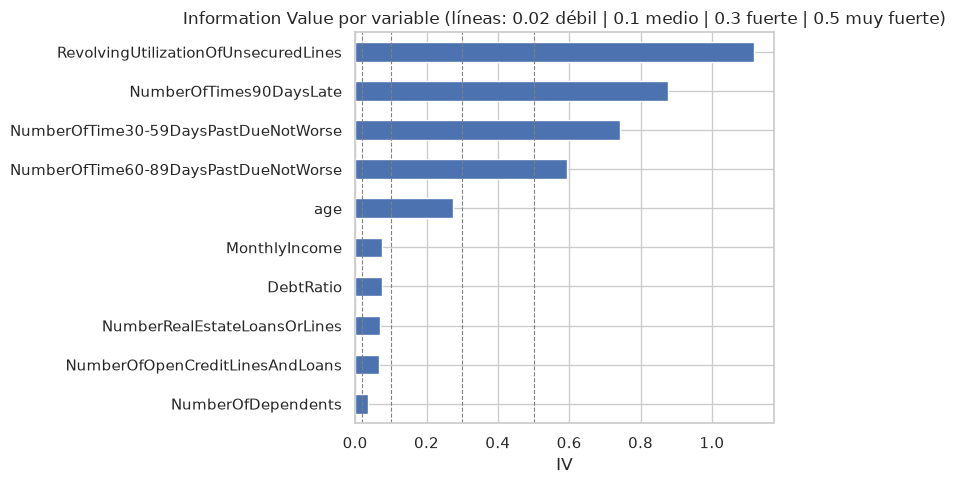

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
iv_serie.sort_values().plot(kind="barh", ax=ax, color="#4c72b0")
for umbral in (0.02, 0.1, 0.3, 0.5):
    ax.axvline(umbral, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Information Value por variable (líneas: 0.02 débil | 0.1 medio | 0.3 fuerte | 0.5 muy fuerte)")
ax.set_xlabel("IV")
plt.tight_layout()
plt.show()

`RevolvingUtilizationOfUnsecuredLines` (IV=1.12) y las tres variables de atraso (entre 0.60 y 0.88) caen justo en esa zona "sospechosamente fuerte" (> 0.5). Pero si lo pensamos tiene sentido porque representan casi la definición de incumplimiento, no es casualidad que predigan tan bien. `age` queda en poder medio (IV=0.27), y el resto (`DebtRatio`, `MonthlyIncome`, líneas de crédito, inmuebles, dependientes) es débil por separado (IV < 0.1), probablemente aporten más si se combinan entre sí.

## 9. ¿Cuánto infla el IV el código centinela 96/98?

Vimos que los códigos 96/98 de las columnas de atraso aparecen como atípicos extremos, aquí vamos a revisar qué pasa si los tratamos como `NaN` (como hicimos arriba) contra dejarlos como si fueran conteos reales.

In [15]:
comparacion_iv = pd.DataFrame({
    "IV_centinela_como_dato": {c: calcular_iv(train, c, TARGET)[1] for c in LATE},
    "IV_centinela_como_NaN": {c: calcular_iv(d, c, TARGET)[1] for c in LATE},
})
comparacion_iv.round(4)

,IV_centinela_como_dato,IV_centinela_como_NaN
NumberOfTime30-59DaysPastDueNotWorse,0.7430,0.7437
NumberOfTimes90DaysLate,0.8776,0.8771
NumberOfTime60-89DaysPastDueNotWorse,0.5969,0.5950


El IV casi no cambia entre ambos tratamientos (menos de 0.002 de diferencia). Esto pasa porque, al limitar los valores en el percentil 99.5% para armar los tramos, el código 98 termina en el mismo grupo que los conteos altos reales, y ambos grupos ya tienen una tasa de impago muy alta, así que el IV no distingue el error. Es una buena noticia para el poder predictivo, pero no significa que podamos dejar el código sin limpiar porque mezclar "98 atrasos" (que no puede ser real) con "3 o 4 atrasos reales" sí puede confundir a un modelo que use la variable en escala continua. Seguimos pensando que lo mejor es convertirlo a `NaN` y agregar una bandera.

## 10. Conclusiones y recomendaciones

Esto es lo que este EDA agrega al de `01_eda.ipynb`:

1. El `Id` no es un índice continuo, e ignorándolo hay 339 filas duplicadas. 
2. Los nulos no son aleatorios: tanto en `MonthlyIncome` como en `NumberOfDependents`, falta el dato con más frecuencia justo en los casos de menor riesgo. Mejor guardarlos como feature (`*_missing`) que sólo imputarlos.
3. El criterio IQR confirma, desde otro ángulo, lo que ya sospechábamos: colas largas en `DebtRatio` y `RevolvingUtilizationOfUnsecuredLines`, y el código 96/98 aislado en las tres columnas de atraso.
4. Hay variables con forma de U que una correlación no detecta:
   - En `NumberOfOpenCreditLinesAndLoans`, el mayor riesgo está en tener cero líneas abiertas (~26% de impago), no en los extremos altos.
   - En `NumberRealEstateLoansOrLines`, el riesgo mínimo está en 1-2 préstamos; tanto 0 como 3-4+ son más riesgosos.
   - La información mutua confirma esto de forma independiente.
5. El Information Value ordena el poder predictivo de cada variable de forma parecida a lo anterior: la utilización de crédito y las tres variables de atraso dominan (incluso "sospechosamente fuerte"), `age` queda en un nivel medio, y el resto es débil por separado.
6. El código 96/98 no distorsiona el IV (termina agrupado con los conteos altos reales), pero de todas formas conviene limpiarlo para no confundir a modelos que usen la variable en escala continua.

Ideas de features que se suman a las ya propuestas:
- `sin_lineas_credito = (NumberOfOpenCreditLinesAndLoans == 0)` como bandera de riesgo.
- Agrupar en tramos `NumberOfOpenCreditLinesAndLoans` y `NumberRealEstateLoansOrLines` si se usa un modelo lineal, por su relación no monótona.
- Usar IV/WOE junto con Spearman e información mutua para decidir qué variables priorizar, y volver a calcularlo después de limpiar los centinelas y armar las nuevas features.
- Mantener las banderas de "faltante" para `MonthlyIncome` y `NumberOfDependents`, ya que la ausencia por sí misma dice algo.

- Si se usa regresión logística como base, probablemente convenga codificar con WOE las variables discretas en vez de dejarlas en escala continua, justamente por ese comportamiento no monótono.